# 7CS353 Machine Learning Lab — Assignment 9
### Clustering: K-Means and Hierarchical

Name: Atharv V Kulkarni
PRN: 245109074
Class: TY CSE(B)

## B1. Explore, Preprocess and Choose k

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
np.random.seed(42)

In [3]:
df = pd.read_csv("customers.csv")
print(df.shape)
print(df.dtypes)
print(df.head())
print(df.describe())
print(df.isnull().sum())

(200, 3)
age              float64
annual_spend     float64
purchase_freq      int64
dtype: object
    age  annual_spend  purchase_freq
0  31.0       1209.59             43
1  40.5       1703.79             25
2  48.5       1254.98             46
3  51.8       1341.83             30
4  37.1       1892.70             30
              age  annual_spend  purchase_freq
count  200.000000    200.000000     200.000000
mean    63.144500   4180.670350      51.350000
std     12.343675   2471.888556      25.699021
min     27.600000    885.160000       1.000000
25%     64.725000   2161.835000      31.000000
50%     70.000000   3574.885000      49.500000
75%     70.000000   5960.895000      71.250000
max     70.000000  11931.690000     114.000000
age              0
annual_spend     0
purchase_freq    0
dtype: int64


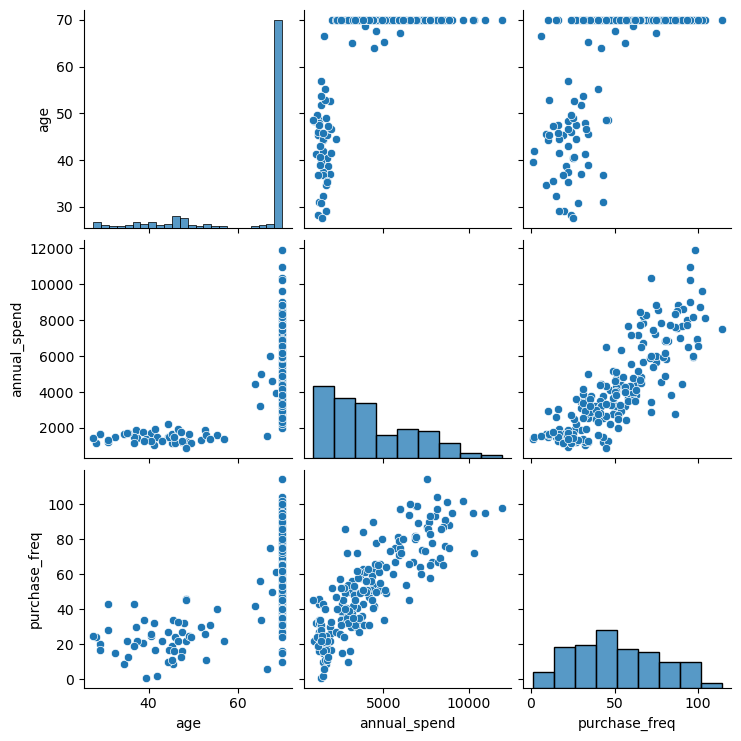

In [4]:
sns.pairplot(df)
plt.show()

In [5]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(df[["age", "annual_spend", "purchase_freq"]])

In [6]:
inertias = []
silhouettes = []
k_range = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(x_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(x_scaled, labels))

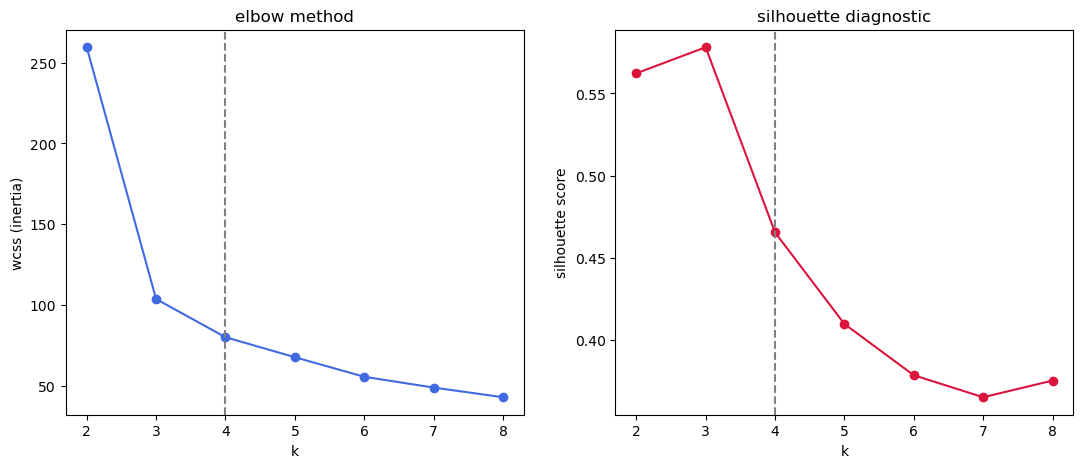

In [22]:
# Elbow method and Silhouette score

# Elbow Method - The elbow method plots (K) against WCSS, also called inertia in scikit-learn's K-Means implementation.
# Silhouette Score - The silhouette score measures whether points are closer to their own cluster than to neighboring clusters.


fig, axes = plt.subplots(1, 2, figsize=(13,5))
axes[0].plot(list(k_range), inertias, marker="o", color="royalblue")
axes[0].axvline(x=4, linestyle="--", color="gray")
axes[0].set_xlabel("k")
axes[0].set_ylabel("wcss (inertia)")
axes[0].set_title("elbow method")

axes[1].plot(list(k_range), silhouettes, marker="o", color="crimson")
axes[1].axvline(x=4, linestyle="--", color="gray")
axes[1].set_xlabel("k")
axes[1].set_ylabel("silhouette score")
axes[1].set_title("silhouette diagnostic")
plt.show()

## B2. K-Means from scratch + sklearn verification

In [8]:
def kmeans_scratch(x, k, max_iter=300, seed=42):
    rng = np.random.default_rng(seed)
    n = x.shape[0]
    idx = rng.choice(n, k, replace=False)
    centroids = x[idx].copy()
    labels = np.zeros(n, dtype=int)
    for iteration in range(max_iter):
        distances = np.linalg.norm(x[:, None, :] - centroids[None, :, :], axis=2)
        new_labels = np.argmin(distances, axis=1)
        if np.array_equal(new_labels, labels) and iteration > 0:
            break
        labels = new_labels
        for i in range(k):
            members = x[labels == i]
            if len(members) > 0:
                centroids[i] = members.mean(axis=0)
    wcss = 0.0
    for i in range(k):
        members = x[labels == i]
        wcss += np.sum((members - centroids[i])**2)
    return labels, centroids, wcss

In [9]:
labels_scratch, centroids_scratch, wcss_scratch = kmeans_scratch(x_scaled, k=4)
print("scratch wcss:", wcss_scratch)
print("scratch centroids:")
print(centroids_scratch)

scratch wcss: 79.98434279070774
scratch centroids:
[[ 0.54530313  0.25225433  0.50704044]
 [-1.67302653 -1.10039371 -1.0939814 ]
 [ 0.55677937  1.53240976  1.33661191]
 [ 0.53108301 -0.4116465  -0.46769993]]


In [10]:
km_sklearn = KMeans(n_clusters=4, n_init=10, random_state=42)
labels_sklearn = km_sklearn.fit_predict(x_scaled)
print("sklearn inertia:", km_sklearn.inertia_)
pct_diff = abs(wcss_scratch - km_sklearn.inertia_) / km_sklearn.inertia_ * 100
print("percentage difference:", pct_diff)

sklearn inertia: 79.98434279070773
percentage difference: 1.776704567341018e-14


In [11]:
pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_scaled)
centroids_pca = pca.transform(km_sklearn.cluster_centers_)

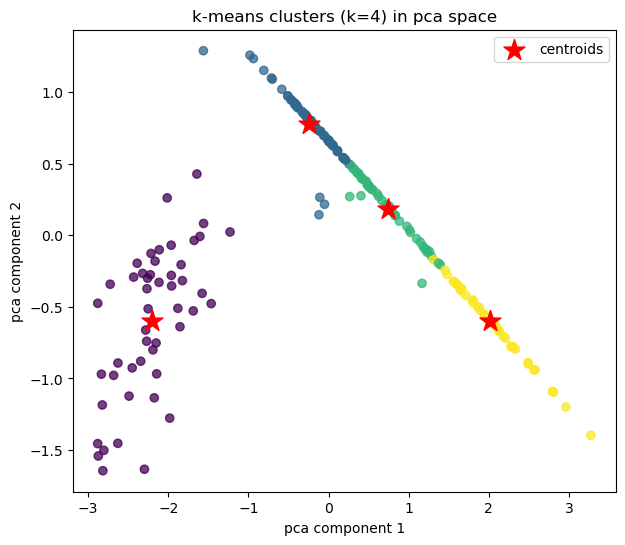

In [12]:
fig, ax = plt.subplots(figsize=(7,6))
scatter = ax.scatter(x_pca[:,0], x_pca[:,1], c=labels_sklearn, cmap="viridis", alpha=0.75)
ax.scatter(centroids_pca[:,0], centroids_pca[:,1], c="red", marker="*", s=250, label="centroids")
ax.set_xlabel("pca component 1")
ax.set_ylabel("pca component 2")
ax.set_title("k-means clusters (k=4) in pca space")
ax.legend()
plt.show()

## B3. Hierarchical clustering and dendrogram

In [13]:
z = linkage(x_scaled, method="ward")

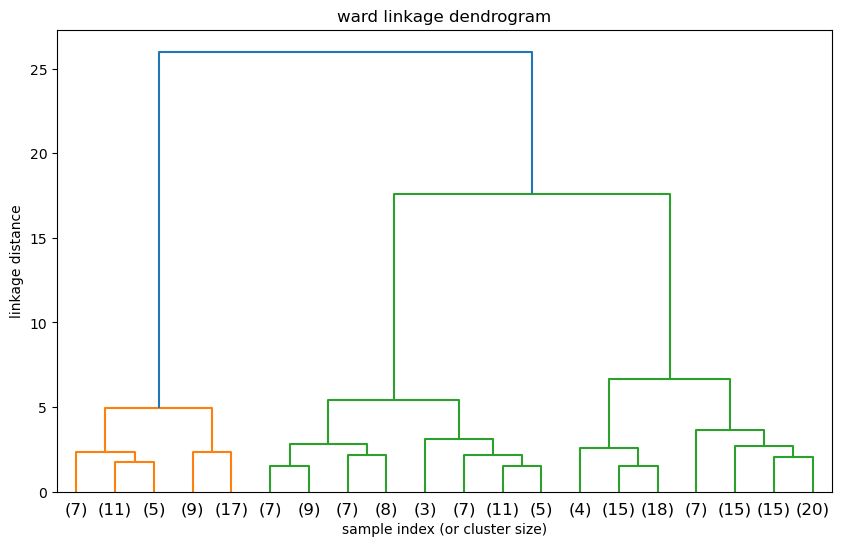

In [14]:
fig, ax = plt.subplots(figsize=(10,6))
dendrogram(z, truncate_mode="lastp", p=20, ax=ax)
ax.set_xlabel("sample index (or cluster size)")
ax.set_ylabel("linkage distance")
ax.set_title("ward linkage dendrogram")
plt.show()

In [15]:
labels_hier = fcluster(z, t=4, criterion="maxclust")
sil_hier = silhouette_score(x_scaled, labels_hier)
db_hier = davies_bouldin_score(x_scaled, labels_hier)
print("hierarchical silhouette:", sil_hier)
print("hierarchical davies-bouldin:", db_hier)

hierarchical silhouette: 0.45589816019358353
hierarchical davies-bouldin: 0.6848316916795553


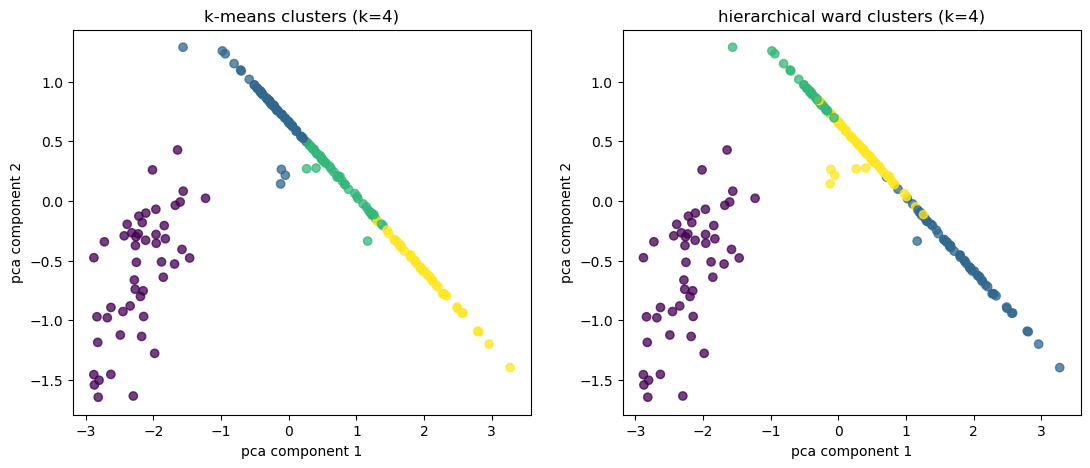

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))
axes[0].scatter(x_pca[:,0], x_pca[:,1], c=labels_sklearn, cmap="viridis", alpha=0.75)
axes[0].set_xlabel("pca component 1")
axes[0].set_ylabel("pca component 2")
axes[0].set_title("k-means clusters (k=4)")

axes[1].scatter(x_pca[:,0], x_pca[:,1], c=labels_hier, cmap="viridis", alpha=0.75)
axes[1].set_xlabel("pca component 1")
axes[1].set_ylabel("pca component 2")
axes[1].set_title("hierarchical ward clusters (k=4)")
plt.show()

## B4. Cluster profiling and algorithm comparison

In [17]:
df_profiled = df.copy()
df_profiled["cluster"] = labels_sklearn
profile = df_profiled.groupby("cluster").agg(
    size=("cluster", "count"),
    mean_age=("age", "mean"),
    mean_annual_spend=("annual_spend", "mean"),
    mean_purchase_freq=("purchase_freq", "mean")
)
print(profile)

         size   mean_age  mean_annual_spend  mean_purchase_freq
cluster                                                        
0          49  42.544898        1467.428367           23.306122
1          61  69.683607        3165.673115           39.360656
2          46  69.858696        4802.654130           64.347826
3          44  70.000000        7959.134773           85.613636


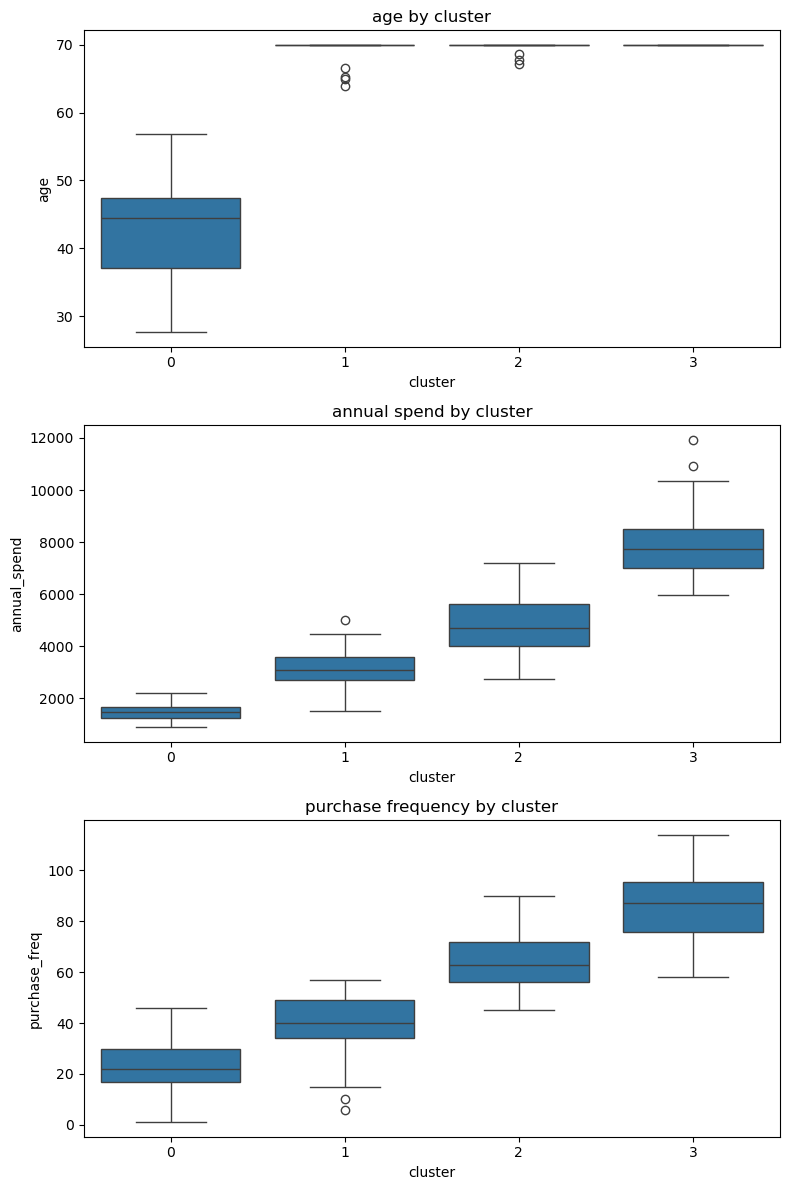

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(8,12))
sns.boxplot(x="cluster", y="age", data=df_profiled, ax=axes[0])
axes[0].set_title("age by cluster")
sns.boxplot(x="cluster", y="annual_spend", data=df_profiled, ax=axes[1])
axes[1].set_title("annual spend by cluster")
sns.boxplot(x="cluster", y="purchase_freq", data=df_profiled, ax=axes[2])
axes[2].set_title("purchase frequency by cluster")
plt.tight_layout()
plt.show()

In [19]:
ch_kmeans = calinski_harabasz_score(x_scaled, labels_sklearn)
ch_hier = calinski_harabasz_score(x_scaled, labels_hier)
sil_kmeans = silhouette_score(x_scaled, labels_sklearn)
db_kmeans = davies_bouldin_score(x_scaled, labels_sklearn)
print("k-means -> silhouette:", sil_kmeans, "davies-bouldin:", db_kmeans, "calinski-harabasz:", ch_kmeans)
print("hierarchical -> silhouette:", sil_hier, "davies-bouldin:", db_hier, "calinski-harabasz:", ch_hier)

k-means -> silhouette: 0.46558548359767277 davies-bouldin: 0.7126791110908632 calinski-harabasz: 424.7625858464152
hierarchical -> silhouette: 0.45589816019358353 davies-bouldin: 0.6848316916795553 calinski-harabasz: 398.1290389168802


#### Cluster 0
##### 49 customers
###### Youngest group on average, with the lowest annual spending and purchase frequency.
###### Possible business description: younger, lower-spending, less frequent buyers.

#### Cluster 1
##### 61 customers
###### Average age is close to 70, with relatively low spending and purchase frequency compared with Clusters 2 and 3.
###### Possible business description: older, moderate-frequency customers with lower spending than the other older groups.

#### Cluster 2
##### 46 customers
###### Average age is close to 70, with higher spending and purchase frequency than Cluster 1.
###### Possible business description: older, higher-frequency customers with relatively high spending.

#### Cluster 3
##### 44 customers
###### Highest mean annual spending and purchase frequency among the four clusters.
###### Possible business description: high-spending, frequent buyers.

## B5. Take-home investigation

In [20]:
km_raw = KMeans(n_clusters=4, n_init=10, random_state=42)
labels_raw = km_raw.fit_predict(df[["age", "annual_spend", "purchase_freq"]].values)
sil_raw = silhouette_score(df[["age", "annual_spend", "purchase_freq"]].values, labels_raw)
print("raw wcss:", km_raw.inertia_, "raw silhouette:", sil_raw)
print("scaled wcss:", km_sklearn.inertia_, "scaled silhouette:", sil_kmeans)

raw wcss: 93782942.94615583 raw silhouette: 0.5694180651681591
scaled wcss: 79.98434279070773 scaled silhouette: 0.46558548359767277


In [21]:
dbscan = DBSCAN(eps=0.5, min_samples=5)
labels_dbscan = dbscan.fit_predict(x_scaled)
n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = np.sum(labels_dbscan == -1)
print("dbscan clusters found:", n_clusters_dbscan)
print("dbscan noise points:", n_noise)

dbscan clusters found: 2
dbscan noise points: 8
